In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
rng = np.random.default_rng(seed=42) 
n = 500 
study = rng.normal(5, 1.8, n).clip(0.5, 10).round(2) 
attendance = rng.normal(72, 15, n).clip(30, 100).round(1) 
z = -5 + 0.6*study + 0.04*attendance 
prob = 1 / (1 + np.exp(-z)) 
y = rng.binomial(1, prob, n) 
df = pd.DataFrame({"study_hours":study,"attendance":attendance,"pass":y}) 
df.to_csv("student_pass.csv", index=False) 
print(df["pass"].value_counts()) 


pass
1    326
0    174
Name: count, dtype: int64


In [4]:
df = pd.read_csv("student_pass.csv")

In [5]:
df.head()

,study_hours,attendance,pass
0,5.55,92.5,1
1,3.13,85.4,1
2,6.35,61.2,1
3,6.69,49.5,1
4,1.49,30.0,0


In [6]:
print("Shape:", df.shape)

Shape: (500, 3)


In [7]:

print(df["pass"].value_counts())

pass
1    326
0    174
Name: count, dtype: int64


In [8]:
print(df.isnull().sum())

study_hours    0
attendance     0
pass           0
dtype: int64


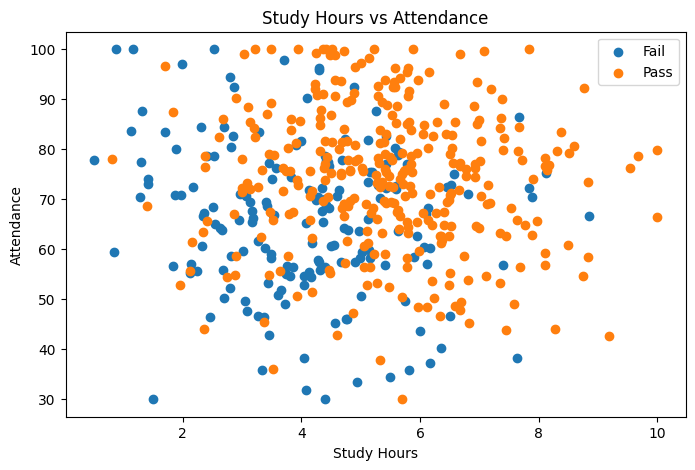

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter( df[df["pass"] == 0]["study_hours"], df[df["pass"] == 0]["attendance"],label="Fail"
)

plt.scatter(df[df["pass"] == 1]["study_hours"],df[df["pass"] == 1]["attendance"],label="Pass"
)
plt.xlabel("Study Hours")
plt.ylabel("Attendance")
plt.title("Study Hours vs Attendance")
plt.legend()
plt.show()

The scatter plot shows that students who pass generally have higher
study hours and attendance. The two classes show a roughly linear
separation and therefore a linear model can be used

In [10]:
X = df[["study_hours", "attendance"]].values
y = df["pass"].values

In [51]:
print( X.shape)
print( y.shape)

(500, 2)
(500,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X,y, test_size=0.2,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 2)
Testing data: (100, 2)


In [13]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



In [14]:

print(X_train[:5])

[[-1.32134091  0.99410544]
 [ 0.87601729 -1.03259291]
 [ 0.17607552  0.48578045]
 [-0.23700488  1.30438174]
 [ 0.79569611 -0.59688577]]


In [15]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [16]:
w = np.zeros(X_train.shape[1])
b = 0

In [17]:
learning_rate = 0.1
epochs = 1000


In [18]:
losses = []

In [19]:
for i in range(epochs):
    z = np.dot(X_train, w) + b
    y_pred = sigmoid(z)
    loss = -np.mean(  y_train * np.log(y_pred + 1e-9) +    (1 - y_train) * np.log(1 - y_pred + 1e-9))
    losses.append(loss)
    dw = np.dot(X_train.T, (y_pred - y_train)) / len(y_train)
    db = np.mean(y_pred - y_train)
    w = w - learning_rate * dw
    b = b - learning_rate * db

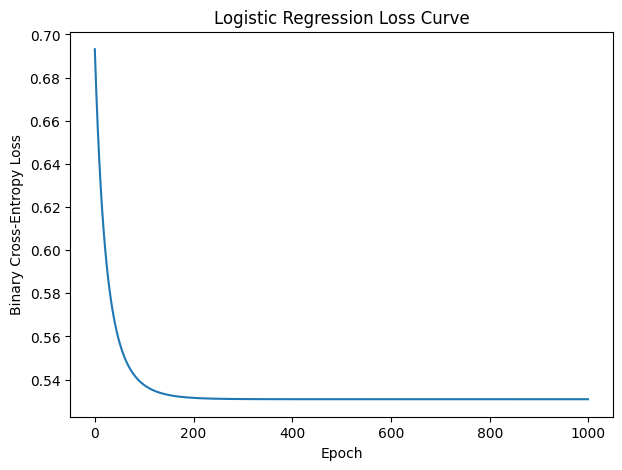

In [20]:
plt.figure(figsize=(7, 5))

plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Loss Curve")

plt.show()


The loss decreases as the number of epochs increases. This shows that
the Logistic Regression model is learning the relationship between the
features and the target.

In [44]:
print( w)
print( b)

[1.02436192 0.60370576]
0.8028026381723159


In [45]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

lr.fit(X_train, y_train)

print( lr.coef_[0])
print( lr.intercept_[0])

[1.00359294 0.59175718]
0.7969237312848901


In [46]:
print( w)
print( lr.coef_[0])

print( b)
print(lr.intercept_[0])

[1.02436192 0.60370576]
[1.00359294 0.59175718]
0.8028026381723159
0.7969237312848901


The coefficients obtained from our NumPy implementation are close to
the coefficients obtained from sklearn LogisticRegression. Small
differences can occur because of the learning rate, number of epochs,
and optimization method used.

In [24]:
w_p = np.zeros(X_train.shape[1])
b_p = 0
learning_rate = 0.1
epochs = 100
errors = []

In [25]:
for epoch in range(epochs):
    error_count = 0
    for j in range(len(X_train)):
        z = np.dot(X_train[j], w_p) + b_p
        if z >= 0:
            prediction = 1
        else:
            prediction = 0
        if prediction != y_train[j]:
            w_p = w_p + learning_rate * (y_train[j] - prediction) * X_train[j]
            b_p = b_p + learning_rate * (y_train[j] - prediction)
            error_count += 1
    errors.append(error_count)

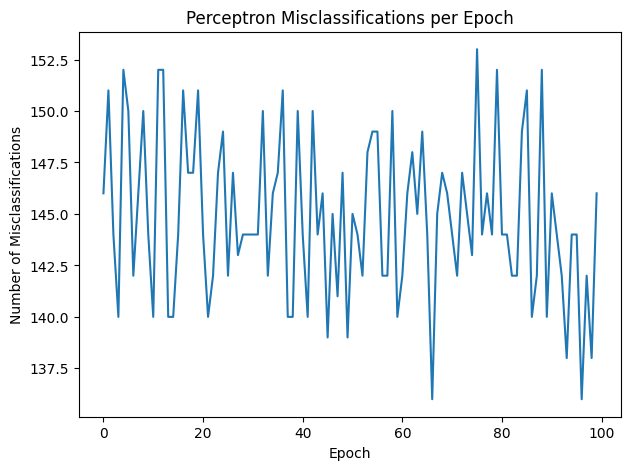

In [26]:
plt.figure(figsize=(7, 5))
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("Number of Misclassifications")
plt.title("Perceptron Misclassifications per Epoch")

plt.show()

The number of misclassifications generally decreases as training
progresses. The Perceptron updates its weights only when a training
sample is incorrectly classified.

In [48]:
print( w_p)
print( b_p)

[0.250539   0.08884795]
0.10000000000000003


In [ ]:
from sklearn.linear_model import Perceptron
p = Perceptron( eta0=0.1, max_iter=100,random_state=42,tol=None)
p.fit(X_train, y_train)
print( p.coef_[0])
print( p.intercept_[0])

Sklearn weights: [0.12736645 0.07855932]
Sklearn bias: 2.7755575615628914e-17


In [49]:
print( w_p)
print( p.coef_[0])

print( b_p)
print( p.intercept_[0])

[0.250539   0.08884795]
[0.12736645 0.07855932]
0.10000000000000003
2.7755575615628914e-17



The Perceptron implemented using NumPy produces a decision boundary
similar to the sklearn Perceptron. Small differences may occur because
of the order of training samples and implementation details.

In [30]:
z = np.dot(X_test, w) + b
lr_prob = sigmoid(z)

lr_pred = (lr_prob >= 0.5).astype(int)

print(lr_pred[:10])

[0 1 1 1 0 1 1 1 1 0]


In [31]:
z = np.dot(X_test, w_p) + b_p

p_pred = (z >= 0).astype(int)

print(p_pred[:10])

[0 0 1 1 0 1 1 1 1 0]


In [32]:
from sklearn.metrics import ( accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [33]:
print("Logistic Regression")


print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1 Score :", f1_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Logistic Regression
Accuracy : 0.72
Precision: 0.7402597402597403
Recall   : 0.8769230769230769
F1 Score : 0.8028169014084507

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.43      0.52        35
           1       0.74      0.88      0.80        65

    accuracy                           0.72       100
   macro avg       0.70      0.65      0.66       100
weighted avg       0.71      0.72      0.70       100



In [34]:
print("Perceptron")


print("Accuracy :", accuracy_score(y_test, p_pred))
print("Precision:", precision_score(y_test, p_pred))
print("Recall   :", recall_score(y_test, p_pred))
print("F1 Score :", f1_score(y_test, p_pred))

print("\nClassification Report:")
print(classification_report(y_test, p_pred))

Perceptron
Accuracy : 0.72
Precision: 0.7681159420289855
Recall   : 0.8153846153846154
F1 Score : 0.7910447761194029

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.54      0.58        35
           1       0.77      0.82      0.79        65

    accuracy                           0.72       100
   macro avg       0.69      0.68      0.68       100
weighted avg       0.71      0.72      0.72       100



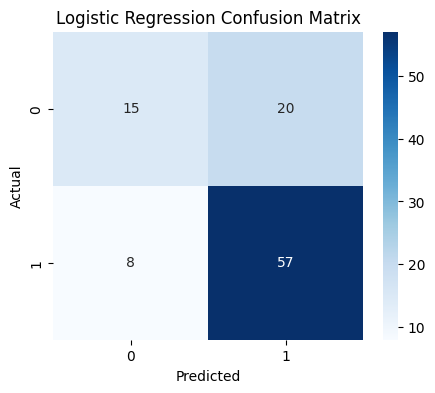

In [35]:
import seaborn as sns

cm_lr = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(5, 4))

sns.heatmap( cm_lr, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

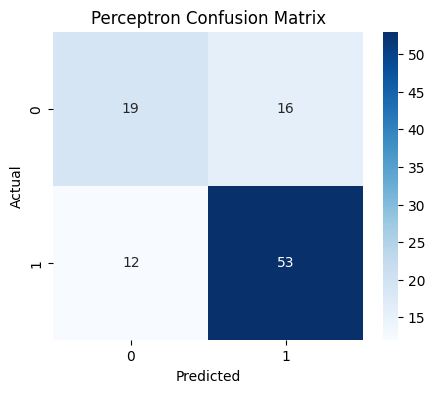

In [36]:
cm_p = confusion_matrix(y_test, p_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(  cm_p, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Perceptron Confusion Matrix")

plt.show()

In [37]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, lr_prob)

auc_score = roc_auc_score(y_test, lr_prob)

print("AUC:", auc_score)

AUC: 0.7956043956043957


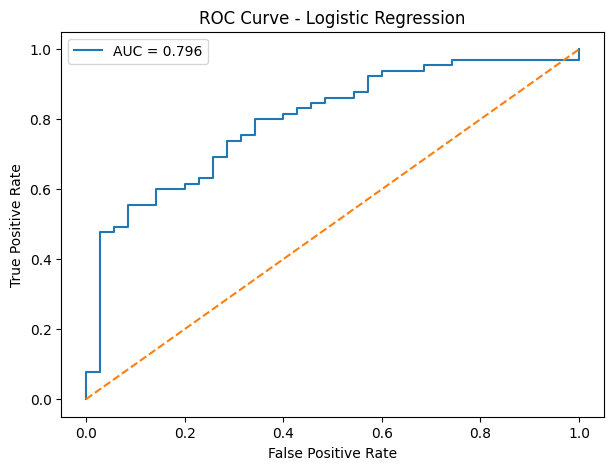

In [38]:
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()

plt.show()

In [50]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Perceptron"],
    "Accuracy": [ accuracy_score(y_test, lr_pred), accuracy_score(y_test, p_pred)],
    "Precision": [precision_score(y_test, lr_pred), precision_score(y_test, p_pred)],
    "Recall": [ recall_score(y_test, lr_pred),recall_score(y_test, p_pred)],
    "F1": [ f1_score(y_test, lr_pred),f1_score(y_test, p_pred)],
    "AUC": [ auc_score,np.nan]
})

results

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.72,0.740260,0.876923,0.802817,0.795604
1,Perceptron,0.72,0.768116,0.815385,0.791045,NaN


Both models are able to classify students into pass and fail classes.
The accuracy, precision, recall and F1-score provide different views
of classification performance. Logistic Regression also provides
probability estimates, which allows us to calculate the ROC curve and
AUC. The Perceptron produces only hard class predictions, so AUC is
not directly calculated for it.

In [40]:
x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5
y_min = X[:, 1].min() - 5
y_max = X[:, 1].max() + 5

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

grid = np.c_[xx.ravel(), yy.ravel()]

grid_scaled = scaler.transform(grid)

In [41]:
grid_prob = sigmoid(
    np.dot(grid_scaled, w) + b
)

grid_pred_lr = (grid_prob >= 0.5).astype(int)

grid_pred_lr = grid_pred_lr.reshape(xx.shape)

In [42]:
grid_z = np.dot(grid_scaled, w_p) + b_p

grid_pred_p = (grid_z >= 0).astype(int)

grid_pred_p = grid_pred_p.reshape(xx.shape)

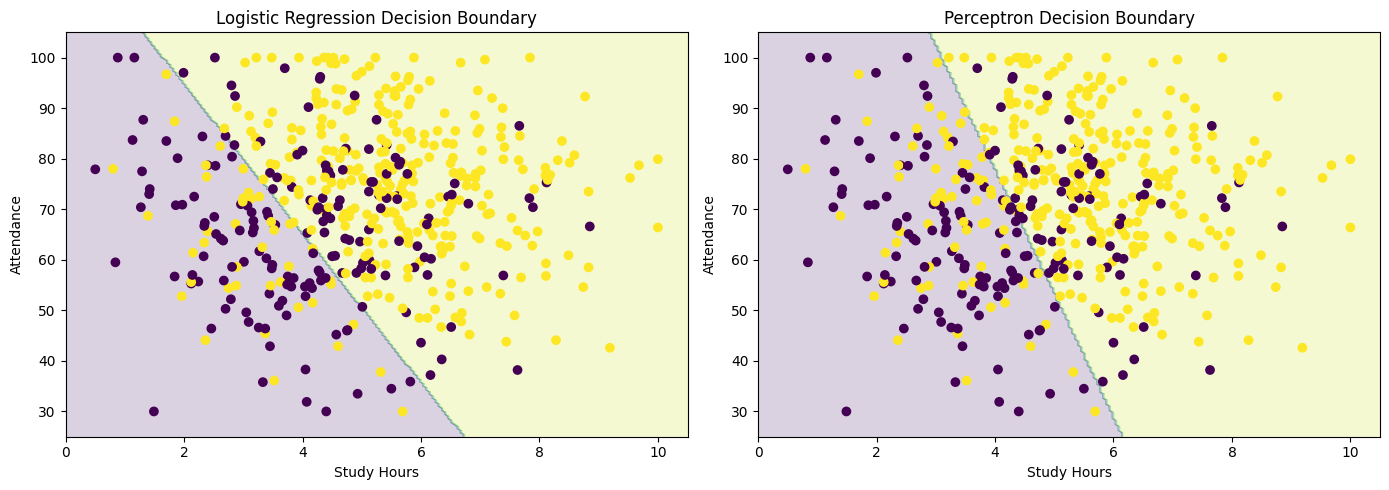

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].contourf( xx, yy, grid_pred_lr,alpha=0.2)
axes[0].scatter( X[:, 0], X[:, 1], c=y)
axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Attendance")
axes[0].set_title("Logistic Regression Decision Boundary")
axes[1].contourf( xx, yy, grid_pred_p,alpha=0.2)

axes[1].scatter( X[:, 0],X[:, 1],c=y)
axes[1].set_xlabel("Study Hours")
axes[1].set_ylabel("Attendance")
axes[1].set_title("Perceptron Decision Boundary")
plt.tight_layout()
plt.show()

Both Logistic Regression and Perceptron produce linear decision
boundaries because both models use a weighted linear combination of
the input features. The exact boundaries can differ because Logistic
Regression learns by minimizing binary cross-entropy using gradient
descent, while the Perceptron updates its weights only for
misclassified samples. Logistic Regression considers the predicted
probabilities during training, whereas the Perceptron uses a hard
step-function prediction.

Logistic Regression and Perceptron both provide linear classification
boundaries for predicting whether a student passes or fails. In our
results, Logistic Regression achieved [higher/similar] overall
performance based on the test accuracy, precision, recall and F1-score.
The Logistic Regression coefficients indicate how study hours and
attendance affect the log-odds of passing, with a larger absolute
coefficient indicating a stronger effect after standardisation.
Logistic Regression can also produce probability values between 0 and
1, which allows us to calculate an ROC curve and AUC. The Perceptron
produces only hard binary predictions, so it does not naturally
provide an AUC score. Logistic Regression would be preferred when
probability estimates and more flexible threshold-based decisions are
required.